# Mizan: EDA
**Final Project: Machine Learning, Group 6**

Exploratory analysis of the main table (`application_train`) of the Home Credit data. The data is not stored in this repository.

## Exploratory Data Analysis (EDA)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload application_train.csv.zip (or the unzipped .csv) to the Files panel on the left first
df = pd.read_csv("application_train.csv.zip")
df.head()

In [15]:
df.shape

(307511, 122)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


### Features we use
| Column | Meaning |
|---|---|
| `AMT_INCOME_TOTAL` | Yearly income of the client |
| `AMT_CREDIT` | Loan amount |
| `AMT_ANNUITY` | Yearly loan payment |
| `AMT_GOODS_PRICE` | Price of the goods the loan is for |
| `CNT_CHILDREN`, `CNT_FAM_MEMBERS` | Number of children and family members |
| `REGION_RATING_CLIENT` | Rating of the client's region (1 = best, 3 = worst) |
| `EXT_SOURCE_1/2/3` | Credit scores from external sources (like a credit bureau), 0 to 1 |
| `DAYS_BIRTH` | Age, counted in days **before** the application (negative numbers) |
| `DAYS_EMPLOYED` | Days employed, also negative |
| `NAME_CONTRACT_TYPE` | Cash loan or revolving loan |
| `FLAG_OWN_CAR`, `FLAG_OWN_REALTY` | Owns a car / a house (Y or N) |
| `NAME_INCOME_TYPE` | Working, pensioner, state servant, unemployed... |
| `NAME_EDUCATION_TYPE` | Education level |
| `NAME_FAMILY_STATUS` | Married, single... |
| `NAME_HOUSING_TYPE` | House, rented, with parents... |
| `OCCUPATION_TYPE` | Job |
| **`TARGET`** | **1 = default, 0 = repaid** |

## Data cleaning

In [17]:
print(df.isna().sum().sum(), "missing values")
print((df.isna().sum() > 0).sum(), "of", df.shape[1], "columns have missing values")
print(df.duplicated().sum(), "duplicated rows")
print((df["DAYS_EMPLOYED"] == 365243).sum(), "rows with DAYS_EMPLOYED = 365243")

9152465 missing values
67 of 122 columns have missing values
0 duplicated rows
55374 rows with DAYS_EMPLOYED = 365243


* **67 of the 122 columns** have missing values. Many are housing columns that are mostly empty, so we will use
  only a set of clear columns and fill the gaps in the preprocessing step.
* **No duplicated rows.**
* `DAYS_EMPLOYED = 365,243` days (about **1,000 years**) appears in **55,374 rows**. This is impossible:
  it is a code for clients with no job (mostly pensioners). We will replace it with "missing" and add a flag column.

## Target

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.919
1    0.081
Name: proportion, dtype: float64


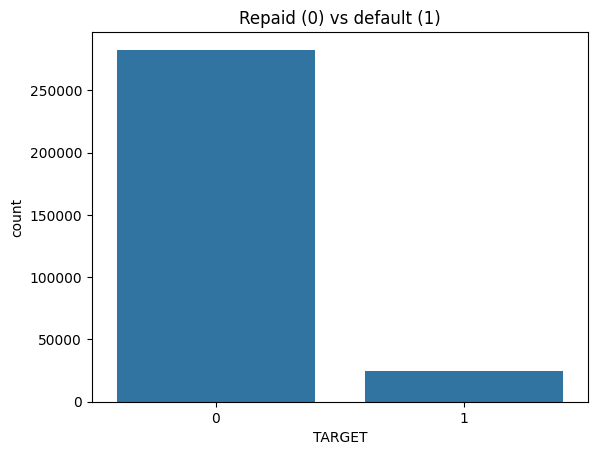

In [18]:
print(df["TARGET"].value_counts())
print(df["TARGET"].value_counts(normalize=True).round(3))
sns.countplot(x="TARGET", data=df)
plt.title("Repaid (0) vs default (1)")
plt.show()

Only **8.1%** of clients defaulted (24,825 of 307,511). The data is **very imbalanced**:
a model that says "repaid" for everyone would get **92% accuracy** and still be useless.
So we will use **class weights** in the models and judge them by **ROC-AUC, Recall and F2**, not accuracy.

In [19]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"].replace(365243, np.nan) / 365
df[["AGE_YEARS", "YEARS_EMPLOYED"]].describe().round(1)

,AGE_YEARS,YEARS_EMPLOYED
count,307511.0,252137.0
mean,43.9,6.5
std,12.0,6.4
min,20.5,-0.0
25%,34.0,2.1
50%,43.2,4.5
75%,53.9,8.7
max,69.1,49.1


Days are negative because they are counted backwards, so we turned them into positive **years**.

# H1

Younger clients default more often.

AGE_GROUP
(20, 30]    11.5
(30, 40]     9.6
(40, 50]     7.7
(50, 60]     6.1
(60, 70]     4.9
Name: TARGET, dtype: float64


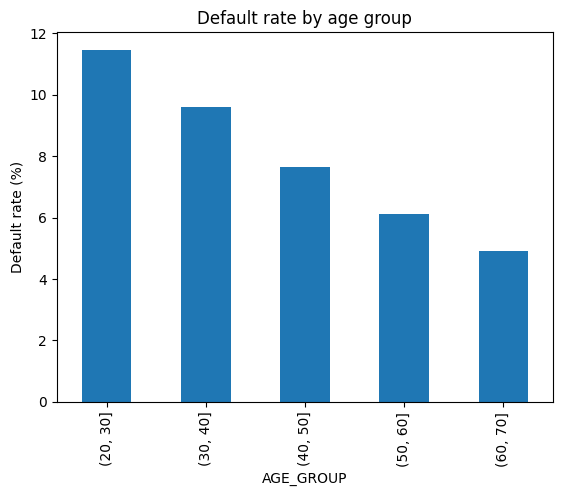

In [20]:
df["AGE_GROUP"] = pd.cut(df["AGE_YEARS"], [20, 30, 40, 50, 60, 70])
print((df.groupby("AGE_GROUP", observed=True)["TARGET"].mean() * 100).round(1))
(df.groupby("AGE_GROUP", observed=True)["TARGET"].mean() * 100).plot(kind="bar")
plt.ylabel("Default rate (%)")
plt.title("Default rate by age group")
plt.show()

# A1
**Confirmed.** Clients aged 20-30 default about **11.5%** of the time, clients aged 60-70 only about **5%**.
The default rate goes down with every age group.

# H2

Clients with higher education default less.

NAME_EDUCATION_TYPE
Academic degree                   1.8
Higher education                  5.4
Incomplete higher                 8.5
Secondary / secondary special     8.9
Lower secondary                  10.9
Name: TARGET, dtype: float64


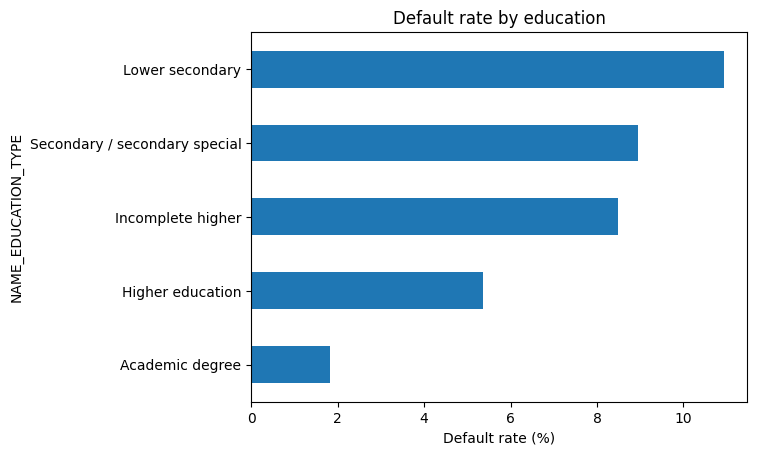

In [21]:
rate = (df.groupby("NAME_EDUCATION_TYPE")["TARGET"].mean() * 100).sort_values()
print(rate.round(1))
rate.plot(kind="barh")
plt.xlabel("Default rate (%)")
plt.title("Default rate by education")
plt.show()

# A2
**Confirmed.** Clients with lower secondary education default about **11%** of the time,
clients with an academic degree under **2%**.

# H3

Clients without a stable income (unemployed, maternity leave) default more.

In [22]:
print(df.groupby("NAME_INCOME_TYPE")["TARGET"].agg(["mean", "count"]).round(3))

                       mean   count
NAME_INCOME_TYPE                   
Businessman           0.000      10
Commercial associate  0.075   71617
Maternity leave       0.400       5
Pensioner             0.054   55362
State servant         0.058   21703
Student               0.000      18
Unemployed            0.364      22
Working               0.096  158774


# A3
**Confirmed, but for very few clients.** Unemployed clients and clients on maternity leave default **over 35%**
of the time, but there are only a few of them. Pensioners and state servants default the least.

# H4

Clients with a lower external credit score default more.

        EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3
TARGET                                          
0              0.511         0.523         0.521
1              0.387         0.411         0.391


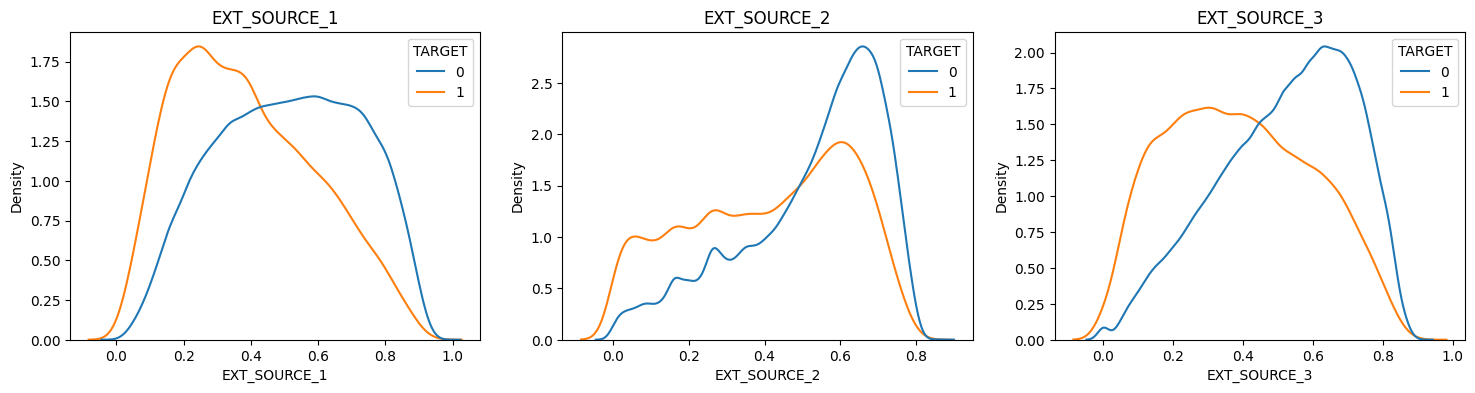

In [23]:
print(df.groupby("TARGET")[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean().round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, col in enumerate(["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=df, x=col, hue="TARGET", common_norm=False, ax=ax[i])
    ax[i].set_title(col)
plt.show()

# A4
**Confirmed, and it is the strongest signal.** In all three scores, clients who defaulted have a **lower average**,
and their curves are shifted to the left. The external credit score is the "credit record health" of the client.

### Gender and age: a fairness note
* **Gender:** a bank should not decide a loan because of a client's gender. So we **do not use `CODE_GENDER` in the model**;
  we only use it at the end to **check fairness** (are women and men approved at similar rates?).
* **Age:** age clearly affects the risk (H1), so we keep it as a feature, and the fairness check makes sure the
  model's decisions stay fair.

## Correlation

In [24]:
corr = df.select_dtypes("number").drop(columns=["TARGET", "SK_ID_CURR"]).corrwith(df["TARGET"])
corr.sort_values(key=abs, ascending=False).head(10).round(3)

,0
EXT_SOURCE_3,-0.179
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155
AGE_YEARS,-0.078
DAYS_BIRTH,0.078
YEARS_EMPLOYED,-0.075
REGION_RATING_CLIENT_W_CITY,0.061
REGION_RATING_CLIENT,0.059
DAYS_LAST_PHONE_CHANGE,0.055
DAYS_ID_PUBLISH,0.051


# EDA Summary
| | Result |
|---|---|
| Size | 307,511 clients, 122 columns |
| Target | Very imbalanced: 8.1% default |
| Missing values | 67 columns; we use clear columns and fill the gaps |
| Anomaly | `DAYS_EMPLOYED = 365,243` in 55,374 rows (code for no job) |
| H1 Age | Confirmed: 20-30 years 11.5% vs 60-70 years 5% |
| H2 Education | Confirmed: lower secondary 11% vs academic degree under 2% |
| H3 Income type | Confirmed: unemployed and maternity leave over 35% (few clients) |
| H4 Credit score | Confirmed: defaulters have lower external credit scores |
| Gender | Not used in the model (fairness); checked at the end |
